# Descriptive Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import matplotlib.patches as mpatches
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio


pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [2]:
df_ntl = pd.read_csv('data/data_ntl.csv')
df_sue = pd.read_csv('data/data_sue.csv')

## Incremental Scatter Line Plots

In [3]:
variables = ['BSA', 'NDBI', 'NDVI', 'DEM', 'SUHI', 
             'Black Percentile', 'Hispanic Percentile', 
             'White Percentile', 'Median Income Percentile']

In [4]:
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
labels = ['0-10%', '11-20%', '21-30%', '31-40%', '41-50%', '51-60%', '61-70%', '71-80%', '81-90%', '91-100%']
demos = ['Median Income Percentile', 'Black Percentile', 'Hispanic Percentile', 'White Percentile']
for demo in demos:
    df_ntl[demo + ' Binned'] = pd.cut(df_ntl[demo], bins=bins, labels=labels)
    df_sue[demo + ' Binned'] = pd.cut(df_sue[demo], bins=bins, labels=labels)

In [5]:
def scatter_line_plots():
    plt.rc('font', size=16)
    env = ['BSA', 'NDBI', 'NDVI', 'DEM', 'SUHI']
    ylabels = ['$\Delta$'+ e for e in env[:4]] + ['SUHI']
    demo = ['Median Income Percentile', 'Black Percentile', 'Hispanic Percentile', 'White Percentile']
    nrows, ncols = 5, 4
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16,12), constrained_layout=True, sharey='row', dpi=1000)
    for i in range(ncols):
        for j in range(nrows):          
            temp_sue = pd.DataFrame(df_sue.groupby(demo[i]+' Binned')[env[j]].mean()).reset_index()
            temp_ntl  = pd.DataFrame(df_ntl.groupby(demo[i]+' Binned')[env[j]].mean()).reset_index()
            
            axes[j,i].scatter(temp_sue[demo[i]+' Binned'], temp_sue[env[j]], color='blue')
            axes[j,i].plot(temp_sue[demo[i]+' Binned'], temp_sue[env[j]], color='blue')
            axes[j,i].plot([], [], '-o', color='blue', label = 'SUE')
            
            axes[j,i].scatter(temp_ntl[demo[i]+' Binned'], temp_ntl[env[j]], color='red')
            axes[j,i].plot(temp_ntl[demo[i]+' Binned'], temp_ntl[env[j]], color='red')
            axes[j,i].plot([], [], '-o', color='red', label = 'NTL')

            axes[j,i].set_xticks([])  # Remove y-axis ticks

    axes[0,0].legend(bbox_to_anchor=(0.45,1.2), loc='center', ncol=2)
    for a in range(len(ylabels)):
        axes[a,0].set_ylabel(ylabels[a])
    labels = ['0-10%', '11-20%', '21-30%', '31-40%', '41-50%', '51-60%', '61-70%', '71-80%', '81-90%', '91-100%']
    for b in range(ncols):
        axes[-1,b].set_xlabel(demo[b])
        axes[-1,b].set_xticks(labels)
        axes[-1,b].tick_params("x", rotation=45)
    plt.rc('font', size=16)
    plt.savefig('graphs/descriptive/scatter_line_comparison_percentiles.jpg', bbox_inches='tight', dpi=1000)

In [19]:
plt.rc('font', size=16)
scatter_line_plots()

In [7]:
plt.rc('font', size=16)
scatter_line_plots()

## Violin Plot Comparison

### Urban Summaries

In [8]:
variables = ['BSA', 'NDBI', 'NDVI', 'DEM', 'SUHI', 
             'Black', 'Hispanic', 'White', 'Below Poverty']
summ_df = pd.DataFrame()
for variable in variables:
    summ_df[variable] = df_ntl.groupby('Urban_name')[variable].mean()
summ_df = summ_df.reset_index()
summ_df.head()

,Urban_name,BSA,NDBI,NDVI,DEM,SUHI,Black,Hispanic,White,Below Poverty
0,"Aberdeen--Bel Air South--Bel Air North, MD",-0.023035,0.015893,-0.010263,-14.211530,1.996904,15.316692,4.765658,78.263699,6.905660
1,"Abilene, TX",0.010149,-0.030862,-0.051036,-1.785209,-0.525348,10.174689,28.336249,61.730950,17.916667
2,"Aguadilla--Isabela--San Sebastián, PR",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Akron, OH",-0.020566,0.051806,-0.087637,-7.024440,4.585945,18.986343,2.139514,77.371852,16.945205
4,"Albany, GA",-0.009210,0.037079,-0.059954,-0.503401,3.061102,65.055291,3.098747,33.729082,27.866667


In [9]:
variables = ['BSA', 'NDBI', 'NDVI', 'DEM', 'SUHI',
             'Black', 'Hispanic', 'White', 'Below Poverty']
summ_df2 = pd.DataFrame()
for variable in variables:
    summ_df2[variable] = df_sue.groupby('Urban_name')[variable].mean()
summ_df2 = summ_df2.reset_index()
summ_df2.head()

,Urban_name,BSA,NDBI,NDVI,DEM,SUHI,Black,Hispanic,White,Below Poverty
0,"Aberdeen--Bel Air South--Bel Air North, MD",-0.004963,0.029992,-0.057620,-9.799986,1.639363,12.943396,4.264151,75.584906,6.905660
1,"Abilene, TX",0.006962,-0.062125,-0.010939,-54.596603,1.104115,8.750000,27.805556,58.250000,17.916667
2,"Aguadilla--Isabela--San Sebastián, PR",0.002429,0.044546,-0.021673,-116.950916,1.114525,2.243243,96.445946,1.932432,52.729730
3,"Akron, OH",-0.009488,0.046275,-0.093324,-5.083675,2.789590,16.244898,1.721088,74.843537,16.877551
4,"Albany, GA",-0.002130,0.046828,-0.099490,-6.747280,2.945222,63.500000,2.666667,29.666667,27.866667


In [10]:
urban_df = pd.read_csv('data/Census_UHI_US_Urbanized_climzone_metadata.csv', usecols=['Urban_name', 'Clim_zone', 'Coastal?'])

In [11]:
summ_df = summ_df.merge(urban_df, on='Urban_name', how='left')
summ_df2 = summ_df2.merge(urban_df, on='Urban_name', how='left')
summ_df.rename(columns={'Clim_zone':'Climate Zone'}, inplace=True)
summ_df2.rename(columns={'Clim_zone':'Climate Zone'}, inplace=True)

### Violin Plots

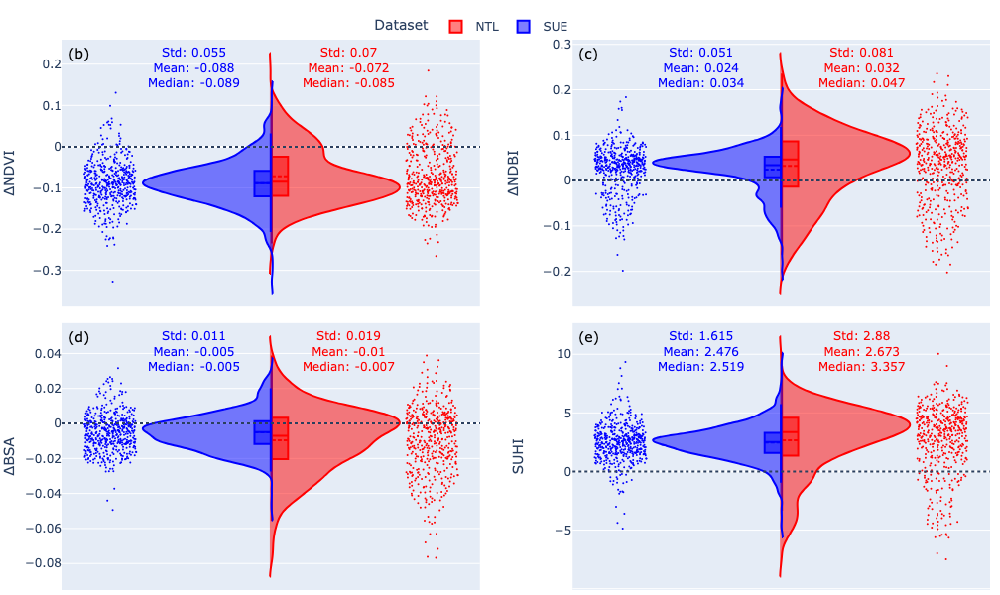

In [20]:
variables = ['NDVI', 'NDBI', 'BSA', 'SUHI']
ylabels = ['\u0394'+x for x in ['NDVI', 'NDBI', 'BSA']] + ['SUHI']
show_legend = [True,False,False,False]
refs = ['(b)', '(c)', '(d)', '(e)']
nrows = 2; ncols = 2
fig = make_subplots(
    rows=nrows, cols=ncols, vertical_spacing= 0.03, horizontal_spacing=0.1
)

idx = 0
for i in range(1,nrows+1):
    for j in range(1,ncols+1):
        fig.add_trace(go.Violin(y=summ_df[variables[idx]],
                                name='NTL',
                                side='positive',
                                #orientation='v',
                                line_color='red', 
                                box_visible=True,
                                meanline_visible=True, 
                                width=90,
                                points='all', marker=dict(size=2),
                                showlegend=show_legend[idx], pointpos=1.25, jitter=0.2
                               ), 
                      row=i, col=j
                     )
        
        fig.add_trace(go.Violin(y=summ_df2[variables[idx]],
                                name='SUE',
                                side='negative',
                                #orientation='v',
                                line_color='blue', 
                                box_visible=True,
                                meanline_visible=True, 
                                width=90,
                                points='all', marker=dict(size=2),
                                showlegend=show_legend[idx], pointpos=-1.25, jitter=0.2
                               ), 
                      row=i, col=j
                     )
        fig.add_hline(y=0, line_dash='dot')
        fig.update_xaxes(showticklabels=False, row=i, col=j)
        fig.update_yaxes(title=ylabels[idx], row=i, col=j)
        fig.add_annotation(xref='x domain',
                   yref='y domain',
                   x=0.80,
                   y=0.99,
                   text= 'Std: ' + str(round(summ_df[variables[idx]].std(), 3)) + '<br>Mean: ' + str(summ_df[variables[idx]].mean().round(3)) + '<br>Median: ' + str(summ_df[variables[idx]].round(3).median()),
                   showarrow=False,
                   font=dict(
                    #size=12,
                    color="red",
                   ),
                   row=i, col=j)
        fig.add_annotation(xref='x domain',
                   yref='y domain',
                   x=0.2,
                   y=0.99,
                   text= 'Std: ' + str(round(summ_df2[variables[idx]].std(), 3)) + '<br>Mean: ' + str(summ_df2[variables[idx]].mean().round(3)) + '<br>Median: ' + str(summ_df2[variables[idx]].round(3).median()),
                   showarrow=False,
                   font=dict(
                    #size=12,
                    color="blue",
                   ),
                   row=i, col=j)
        fig.add_annotation(xref='x domain',
                   yref='y domain',
                   x=0.01,
                   y=0.99,
                   text=refs[idx],
                   showarrow=False,
                   font=dict(
                    size=14,
                    color="black",
                   ),
                   row=i, col=j)
        
        idx+=1
fig.update_layout(
    legend_title_text='Dataset', 
    legend=dict(
    orientation="h",
    yanchor="top",
    y=1.05,
    xanchor="right",
    x=0.55,
        bgcolor="rgba(0,0,0,0)"
    ),
    #showlegend=True, 
    height=600, width=900,
    margin={'t':40,'l':0,'b':0,'r':10},
    violingap=0
)
pio.write_image(fig, 'graphs/descriptive/biophysical_comparison.jpg', scale=2)
pio.write_image(fig, 'graphs/descriptive/biophysical_comparison.svg', scale=2)
fig.show()

In [13]:
from scipy.stats import mannwhitneyu, kstest

In [14]:
ndvi_pval = kstest(df_ntl['NDVI'], df_sue['NDVI'])[1]
ndbi_pval = kstest(df_ntl['NDBI'], df_sue['NDBI'])[1]
bsa_pval  = kstest(df_ntl['BSA'], df_sue['BSA'])[1]
suhi_pval = kstest(df_ntl['SUHI'], df_sue['SUHI'])[1]

In [15]:
ndvi_pval, ndbi_pval, bsa_pval, suhi_pval

(4.697787904229416e-202, 2.848982278863703e-113, 0.0, 1.0304027942474809e-98)

In [16]:
_, ndvi_pval = mannwhitneyu(df_ntl['NDVI'], df_sue['NDVI'], nan_policy='omit')
_, ndbi_pval = mannwhitneyu(df_ntl['NDBI'], df_sue['NDBI'], nan_policy='omit')
_, bsa_pval  = mannwhitneyu(df_ntl['BSA'], df_sue['BSA'], nan_policy='omit')
_, suhi_pval = mannwhitneyu(df_ntl['SUHI'], df_sue['SUHI'], nan_policy='omit')

In [17]:
ndvi_pval, ndbi_pval, bsa_pval, suhi_pval

(4.316159258590317e-233,
 8.66240667848612e-10,
 2.0959608191194983e-205,
 2.2921163264224252e-28)

## Correlation Comparison 

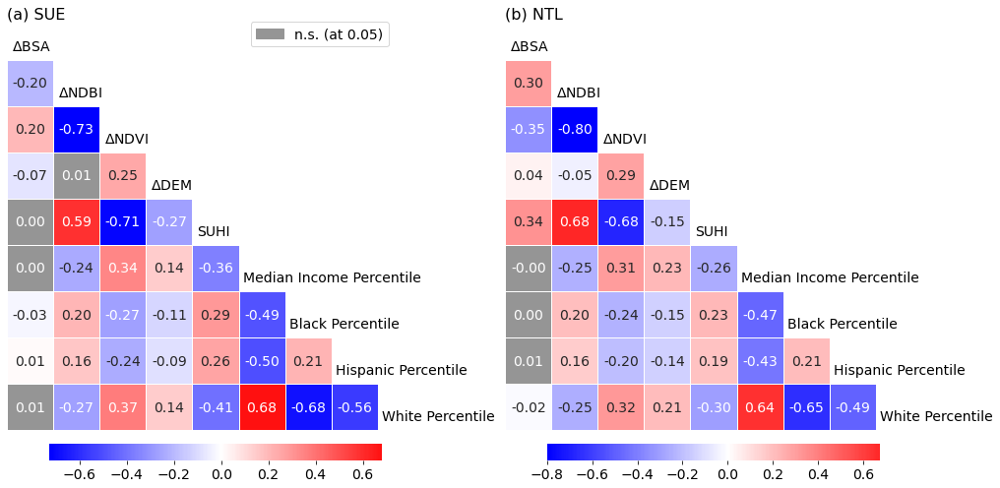

In [18]:
plt.rc('font', size=14)
variables = ['BSA', 'NDBI', 'NDVI', 'DEM', 'SUHI', 
             'Median Income Percentile', 'Black Percentile', 'Hispanic Percentile', 'White Percentile']

labels    = ['$\Delta$BSA', '$\Delta$NDBI', '$\Delta$NDVI', '$\Delta$DEM', 'SUHI',  
             'Median Income Percentile', 'Black Percentile', 'Hispanic Percentile', 'White Percentile']

psig = 0.05 # set the significance threshold
ncols = 2
pvals1 = df_sue[variables].corr(method=lambda x, y: spearmanr(x, y)[1]) - np.eye(*df_sue[variables].corr().shape)
pvals2 = df_ntl[variables].corr(method=lambda x, y: spearmanr(x, y)[1]) - np.eye(*df_ntl[variables].corr().shape)

fig,ax = plt.subplots(1, ncols, figsize=(14,9), constrained_layout=True)
dfs = [df_sue, df_ntl]
dfp = [pvals1, pvals2]
ax_titles = ['(a) SUE', '(b) NTL']

for i in range(ncols):
    matrix = dfs[i][variables].corr(method='spearman')
    mask = np.zeros_like(matrix)
    mask[np.triu_indices_from(mask)] = True

    sns.heatmap(matrix[dfp[i]<psig], center = 0, square = True, mask=mask, ax=ax[i], fmt = ".2f", annot= True,
                linecolor='white', linewidths=0.5, xticklabels=False, cmap='bwr',
                cbar_kws = dict(use_gridspec=False,location="bottom", pad=0.02, shrink=0.8));
    sns.heatmap(matrix[dfp[i]>=psig], center = 0, square = True, mask=mask, ax=ax[i], fmt = ".2f", annot= True,
                linecolor='white', linewidths=0.5, xticklabels=False, cmap=sns.color_palette("Greys", n_colors=1, desat=1),
                cbar = False);
    ax[i].tick_params(left = False, labelleft=False) 

    for j, label in enumerate(labels):
        ax[i].text(j + 0.1, j + 0.7, label, ha='left', va='center', fontsize=14)
    
    ax[i].set_title(ax_titles[i], y=0.975, loc='left', fontsize=16) #, weight='bold')
colors = [sns.color_palette("Greys", n_colors=1, desat=1)[0]]
texts = [f"n.s. (at {psig})"]
patches = [ mpatches.Patch(color=colors[i], label="{:s}".format(texts[i]) ) for i in range(len(texts)) ]
ax[0].legend(handles=patches, bbox_to_anchor=(.75, 0.95), loc='center', fontsize=14)
plt.rc('font', size=14)
plt.savefig('graphs/descriptive/bivariate_spearman_correlation.jpg', bbox_inches='tight', dpi=1000)